# General statistics

Computes missing general stats, then plots QC per method (dots = samples).

In [1]:
import re
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import font_manager

sys.path.insert(0, str(Path.cwd().parents[0]))
from cellseg_benchmark._constants import BASE_PATH, main_methods, method_names
from cellseg_benchmark.metrics import clean_method_name, compute_metric_for_all_methods, extract_general_stats, style_stats_panel

cohorts = ["aging", "ABCAtlas", "VizgenMouseBrain"]
tables_dir = Path(BASE_PATH) / "metrics" / "merged" / "benchmark_tables"
out_dir = Path(BASE_PATH) / "metrics" / "merged" / "general_stats"
out_dir.mkdir(exist_ok=True)
plots = Path(BASE_PATH) / "metrics" / "merged" / "plots"
stats = {"volume_final": "Volume (µm³)", "elongation": "Elongation", "intensities_DAPI": "DAPI intensity", "n_counts": "Transcripts per cell", "n_genes": "Genes per cell"}

font_manager.fontManager.addfont(Path(BASE_PATH) / "misc" / "Arial.ttf")
plt.rcParams.update({"font.family": "Arial", "font.size": 6, "axes.titlesize": 7, "axes.labelsize": 7, "axes.linewidth": 0.6,
                     "xtick.major.size": 2.5, "xtick.major.width": 0.6, "ytick.major.size": 0, "svg.fonttype": "none", "pdf.fonttype": 42})
cohort_names = {"aging": "Aging", "ABCAtlas": "ABC Atlas", "VizgenMouseBrain": "Vizgen"}
cohort_colors = {"Aging": "#3B6FB6", "ABC Atlas": "#D17A22", "Vizgen": "#9A4FB3"}
median = dict(estimator="median", errorbar=None, linestyle="none", marker="|", markersize=8, markeredgewidth=1.2, legend=False)
legend = dict(frameon=False, title="", handletextpad=0.3, borderaxespad=0)



/home/ubuntu/miniforge3/envs/seg_postprocessing/lib/python3.12/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


In [2]:
for cohort in cohorts:
    compute_metric_for_all_methods(extract_general_stats, cohort=cohort, results_name="general_stats/general_stats.csv")

gs, density = (pd.concat([pd.read_csv(Path(BASE_PATH) / "metrics" / c / name / f"{name}.csv", index_col=0).assign(cohort=c) for c in cohorts])
               for name in ["general_stats", "cell_density"])
gs = gs.merge(density[["sample", "method", "tissue_mm2"]], on=["sample", "method"], how="left")
gs = gs.query("sample not in ['all', 'all_samples'] and cell_type_revised == 'all'").assign(method=lambda d: d.method.map(clean_method_name))
alls = gs[gs.method.isin(main_methods)].rename(columns=stats).assign(**{"Cells/mm²": lambda d: d.n_cells / d.tissue_mm2})

1/45 extract_general_stats already computed for Proseg_3D_Cellpose_1_nuclei_model. Set overwrite=True to recompute
2/45 extract_general_stats already computed for Baysor_2D_Cellpose_2_DAPI_Transcripts_0.8. Set overwrite=True to recompute
3/45 extract_general_stats already computed for CellSAM_DAPI. Set overwrite=True to recompute
4/45 extract_general_stats already computed for vpt_2D_DAPI_nuclei. Set overwrite=True to recompute
5/45 extract_general_stats already computed for Cellpose_1_nuclei_model. Set overwrite=True to recompute
6/45 extract_general_stats already computed for Baysor_2D_Cellpose_2_DAPI_PolyT_0.2. Set overwrite=True to recompute
7/45 extract_general_stats already computed for Baysor_2D_Cellpose_1_DAPI_Transcripts_0.8. Set overwrite=True to recompute
8/45 extract_general_stats already computed for Negative_Control_Rastered_5. Set overwrite=True to recompute
9/45 extract_general_stats already computed for Cellpose_2_DAPI_PolyT. Set overwrite=True to recompute
10/45 extra

## Methods

Ordered by overall score, as in the benchmark table (`all/combined.csv` from metrics_summary_table). Dots = samples (coloured by cohort), bar = median. Plotted next to QC below, rows shared.


In [3]:
methods = [m for m in pd.read_csv(tables_dir / "all" / "combined.csv").method if m in set(alls.method)]
alls.to_csv(out_dir / "method_general.csv", index=False)

## Quality control

Left to right: transcripts assigned to cells before and after cell QC, share of cells removed by cell QC (mean over samples, then cohorts), and cells kept after QC summed over sections (millions; axis cut at 15M, larger values written next to the bar). Then general stats per method (dots = samples, bar = median).

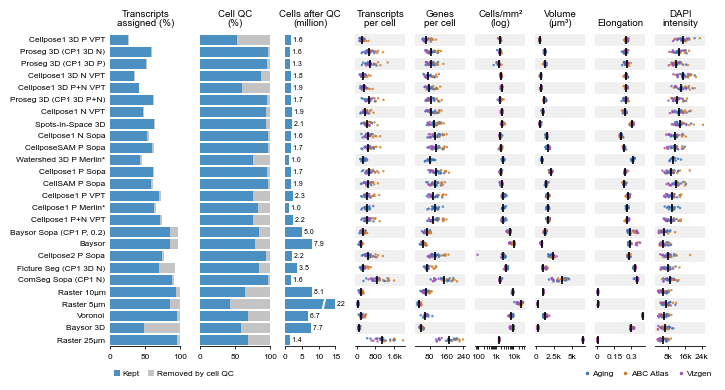

In [4]:
patterns = {
    "start": r"before filtering spatial outliers: (\d+)",
    "Outside tissue": r"after filtering spatial outliers:\s+(\d+)",
    "Low counts or volume": r"after filtering low-quality or volume outliers:\s+(\d+)",
    "Transcript density (top/bottom 1%)": r"during normalization: \d+ -> (\d+)",
}
rows = []
for cohort in cohorts:
    for log in (Path(BASE_PATH) / "misc" / "logs" / "merged").glob(f"merge_adata_{cohort}_*.log"):
        text = log.read_text()
        n = {k: int(m[-1]) if (m := re.findall(p, text)) else None for k, p in patterns.items()}
        raw = log.stem.removeprefix(f"merge_adata_{cohort}_")
        if None not in n.values() and raw in method_names:
            rows.append({"cohort": cohort, "method": clean_method_name(raw)} | n)
qc = pd.DataFrame(rows)
steps = list(patterns)[1:]
left = qc[["start", *steps]].to_numpy()
qc[steps] = 100 * (left[:, :-1] - left[:, 1:]) / qc[["start"]].to_numpy()

tx = pd.concat([pd.read_csv(Path(BASE_PATH) / "metrics" / c / "assigned_transcripts/assigned_transcript_counts.csv", index_col=0).assign(cohort=c) for c in cohorts])
tx = (tx.query("sample not in ['all', 'all_samples']").groupby(["cohort", "sample", "method"])[["assigned_count_raw", "assigned_count_qced", "total_count"]].sum()
      .pipe(lambda d: pd.DataFrame({"Transcripts removed (%)": 100 * (1 - d.assigned_count_qced / d.assigned_count_raw),
                                    "Before QC": 100 * d.assigned_count_raw / d.total_count, "After QC": 100 * d.assigned_count_qced / d.total_count}))
      .groupby(["cohort", "method"]).mean().reset_index())
tx["method"] = tx.method.map(clean_method_name)
qc = qc.merge(tx, on=["cohort", "method"], how="left")
qc = qc[qc.method.isin(methods)]
qc.to_csv(out_dir / "method_qc.csv", index=False)

mean = qc.groupby("method")[[*steps, "Before QC", "After QC"]].mean().reindex(methods)
kept_cells = (qc.start * (1 - qc[steps].sum(axis=1) / 100)).groupby(qc.method).sum().reindex(methods) / 1e6
y = range(len(methods))
kept, removed = "#4a90c2", "#c4c4c4"
bar = dict(height=0.8, lw=0)
n, W = len(methods), 7.2
top, bottom = 0.34, 0.42
H = top + n * 0.1 + bottom
widths, gaps = [0.7, 0.7, 0.5] + [0.5] * 6, [0.2, 0.15, 0.2] + [0.1] * 5
fig = plt.figure(figsize=(W, H))
x = 1.15 + np.concatenate([[0], np.cumsum(np.add(widths[:-1], gaps))])
axes = [fig.add_axes([xi / W, bottom / H, wi / W, n * 0.1 / H]) for xi, wi in zip(x, widths)]
for a in axes[1:]:
    a.sharey(axes[0])

ax2, ax, ax3 = axes[:3]
ax.barh(y, 100 - mean[steps].sum(axis=1), color=kept, **bar)
ax.barh(y, mean[steps].sum(axis=1), left=100 - mean[steps].sum(axis=1), color=removed, **bar)
ax2.barh(y, mean["After QC"], color=kept, **bar)
ax2.barh(y, mean["Before QC"] - mean["After QC"], left=mean["After QC"], color=removed, **bar)
cap = 15
ax3.barh(y, kept_cells.clip(upper=cap), color=kept, **bar)
for i, v in enumerate(kept_cells):
    ax3.text(min(v, cap), i, f" {v:.1f}" if v < 10 else f" {v:.0f}", va="center", fontsize=5)
    if v > cap:
        ax3.plot([0.75 * cap, 0.8 * cap], [i + 0.45, i - 0.45], color="white", lw=1.5)
style_stats_panel(ax3, "Cells after QC (million)", n, zebra=False)
ax3.set(xlim=(0, cap), xticks=[0, 5, 10, 15])
for a, col in [(ax, "Cell QC\n(%)"), (ax2, "Transcripts\nassigned (%)")]:
    style_stats_panel(a, col, n, zebra=False)
    a.set_title(col)
    a.set(xlim=(0, 100), xticks=[0, 50, 100])

for a, col in zip(axes[3:], ["Transcripts per cell", "Genes per cell", "Cells/mm²", "Volume (µm³)", "Elongation", "DAPI intensity"]):
    kw = dict(data=alls, x=col, y="method", order=methods, ax=a)
    sns.stripplot(**kw, hue=alls.cohort.map(cohort_names), palette=cohort_colors, size=1.8, jitter=0.15, linewidth=0, alpha=0.8, legend=False)
    sns.pointplot(**kw, color="black", **(median | {"markersize": 6, "zorder": 3}))
    style_stats_panel(a, col, n)

axes[0].set_yticks(y, [m + "*" if "Merlin" in m else m for m in methods])
axes[0].tick_params(axis="y", length=0)
for a in axes[1:]:
    a.tick_params(axis="y", left=False, labelleft=False)
sq = lambda c, l, **k: plt.Line2D([], [], marker="s", ls="", ms=4, mew=0, color=c, label=l, **k)
fig.legend(handles=[sq(kept, "Kept"), sq(removed, "Removed by cell QC")],
           loc="lower left", bbox_to_anchor=(x[0] / W, 0.02), ncol=2, columnspacing=1, handlelength=0.8, **legend)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=2.5, mew=0, color=v, label=k) for k, v in cohort_colors.items()],
           loc="lower right", bbox_to_anchor=(1, 0.02), ncol=3, columnspacing=1, handlelength=0.8, **legend)
for ext in ["svg", "png"]:
    fig.savefig(plots / f"method_qc.{ext}", dpi=600, transparent=True)